### 1. Make sure the data is correctly shown
Read and rename the CSV and its column/row names to make it easier to code the graph:

In [2]:
import pandas as pd

cpi_data = pd.read_csv("cpi_data.csv", skiprows=8) # reading the first few lines causes an error

cpi_data = cpi_data.rename(columns={"STATIC_INFLATIONCALC": "CPI"}) # Shorten the CPI column name.

cpi_data.tail() # Show the five most RECENT observations (LAST five rows)

,date,CPI
1350,2026-05-01,169.6
1351,2026-06-01,169.0
1352,2026-07-01,169.9
1353,2026-08-01,169.8
1354,2026-09-01,170.0


### 2. Create the formula for annual change and plot the two graphs

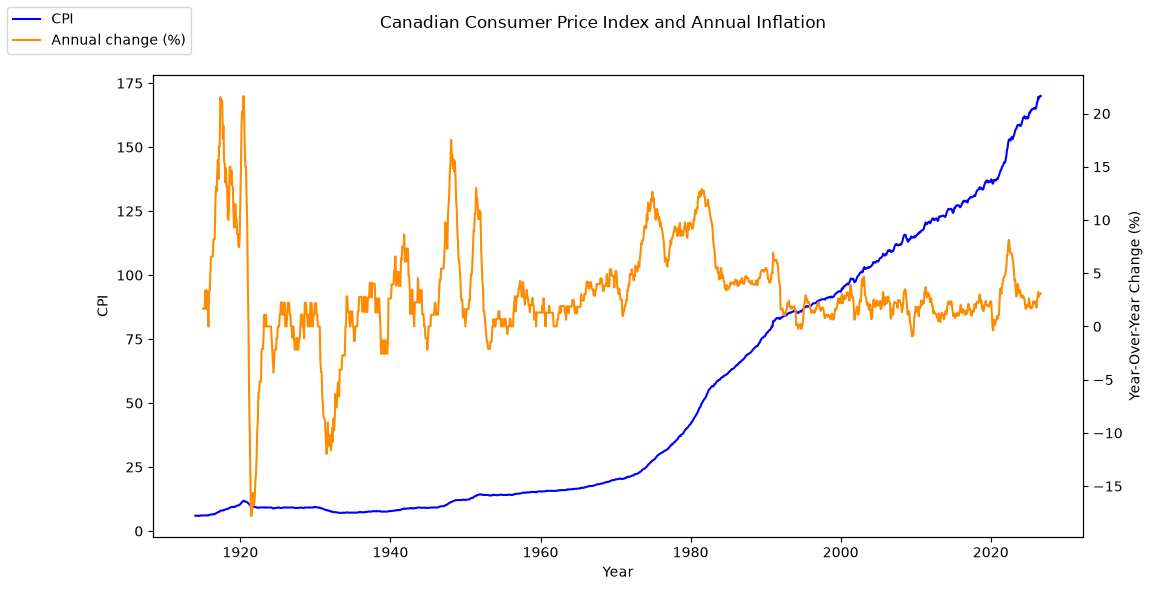

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read and organize the monthly CPI data.
cpi_data = pd.read_csv("cpi_data.csv", skiprows=8) # reading the first 8 rows produces an error because they are not data.
cpi_data.columns = ["Date", "CPI"]
cpi_data = cpi_data.sort_values("Date")

dates = pd.to_datetime(cpi_data["Date"])
cpi = np.array(cpi_data["CPI"])

# Compare each month with the same month one year earlier.
annual_change = (cpi[12:] - cpi[:-12]) / cpi[:-12] * 100

'''NOTES:
cpi[12:] selects everything from the 13th observation onward, starting in January 1915.
cpi[:-12] selects everything except the last 12 observations, starting in January 1914.'''

# Plot CPI on the left axis.
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(dates, cpi, color="blue", label="CPI")

ax1.set_xlabel("Year")
ax1.set_ylabel("CPI")

# Plot annual percentage change on the right axis.
ax2 = ax1.twinx()

ax2.plot(dates[12:], annual_change, color="darkorange", label="Annual change (%)")

ax2.set_ylabel("Year-Over-Year Change (%)")

# Add the title and legend.
fig.suptitle("Canadian Consumer Price Index and Annual Inflation")

fig.legend(loc="upper left")

plt.savefig("CPI_Graph.png", dpi=300, bbox_inches="tight")
plt.show()